# 阶段 3：阈值与判据 —— 怎么自动判定变了、阈值定在哪

> **阶段定位**：第 6–8 周｜过关产出（[阅读路线](../00-总览/阅读路线.md) 阶段 3）= **γ 扫描曲线**（横轴策动力幅值、纵轴判据值，标出临界点 γ_c）+ **判态算法伪代码**（输入 x(t) → 输出 0/1）+ **盲区出现的初相位区间**。

## 阅读导航

| 节 | 内容 | 对应产出 |
|---|---|---|
| 0 | 环境与公共工具：导入 / 参数 / 仿真器 / 三个判据 / 冒烟自检 | 可复用的 `simulate()` |
| 1 | 问 1：三种判据各自的局限 | 「避坑表」 |
| 2 | 问 2：0-1 test 的 K 怎么修正、含噪怎么漂移 | 两态次序核对 |
| 3 | 过关产出①：γ 扫描与临界点 γ_c | 扫描曲线 + 两个 γ_c |
| 4 | 过关产出②③：判态伪代码 + 初相位盲区 | 伪代码 + 极坐标盲区图 |
| 5 | 回扣阶段 2：哪个 R 是真频率 | 谱峰占比 ρ |
| 6 | 结果汇总 | JSON |

**本阶段要回答的四个问题**（阅读路线阶段 3「带着问题读」）：
1. 相图分割法、二分法、Lyapunov 指数法各自的局限是什么？
2. 为什么需要多尺度熵？0-1 test 的 K 值在含噪时怎么修正？
3. 同频不同初相位为什么会漏检，阵列全相位覆盖怎么补？
4. （承阶段 2）锁频伪相变里，哪个 R 才是真频率？——本阶段给可计算的回答。

**来源**：判据综述与 MsEn 算法据 B1（黄泽徽等，物理学报 2020, 69(16):160501，本地全文）；盲区解析式据 [阶段 1 问题销账 Q7](../01-阶段一/阶段1-问题销账.md)；0-1 test 据 B3（Gottwald & Melbourne 2004）。

**边界**：本阶段做到「判据对比 + 自动阈值 + 盲区量化 + 伪代码」为止。$P_d/P_{fa}$、ROC、SNR 门限是阶段 4；定点化是阶段 5。

> **先记住三条结论**（后面逐条用实验支撑）：
> 1. 0-1 test 的 $K$ **必须先对每个 $c$ 的相关系数取绝对值，再取中位数**（$K=\mathrm{median}_c|\mathrm{corr}(n,M_c)|$）。早先用带符号中位数得到「混沌 K 更低」是负值污染，不是判据失效；修正后方向符合理论，但幅度远小于 1，须本机定分界。
> 2. MsEn 的容差 $r$ 选错会全塌成 0；调对后 $\Delta M\approx+0.6$ 可稳定区分两态，但仍要配合平稳性判断。
> 3. pstd 不能用幅值门限代替，否则虚警 100%；阈值随步长漂移，须报「带」不报点。
>
> **一句话**：没有一个判据是「拿来就用」的；判据必须在本机条件下重新标定，并连同噪声条件一起报告。

## 0｜环境与公共工具

下面几段代码依次完成：**导入设置 → 路径/存图 → 全局参数 → 仿真器 → 判据函数 → 冒烟自检**。按顺序跑一次即可，后面所有实验都复用这里的 `simulate()` 与判据函数。

> **命名提醒**：阻尼系数记为 `DAMP`（不用 `K`），避免与 0-1 test 的统计量 `K` 撞名。

In [1]:
# 0.1 导入与绘图设置：中文字体 + 统一分辨率，保证图内嵌后可读
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

In [2]:
# 0.2 路径与存图工具：自动找到项目根，图片统一写进「复现输出/」
def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if ((q / '00-总览/阅读路线.md').is_file() or (q / '阅读路线.md').is_file()):
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')   # 必须先 save 再 show
    print(f'[图] {path}')

In [3]:
# 0.3 全局参数：与阶段 2 完全一致，保证阈值可对照
# 模型
DAMP, OMEGA = 0.5, 1.0        # DAMP = x'' 方程里的阻尼 k；OMEGA = 内驱角频率
LAM0, C_TRIG = 0.72, 0.73     # 内驱幅值、工程触发阈值
C_TRIG_REAL = 0.7335           # 阶段 2 精确 2π 插值下的临界阈值（仅备查，不参与计算）
# 积分与采样
H, T, BURN = 0.02, 300.0, 150.0       # 步长、全长、丢弃瞬态
T_FAST, BURN_FAST = 200.0, 100.0      # 扫描用的短窗
T_SLOW, BURN_SLOW = 1200.0, 600.0     # 判据对照用长窗：λ 靠近 λc 时瞬态可达数百秒
# 判据门限
PSTD_TH = 0.08                        # Poincaré 离散度门限（阶段 2 标定）
_START = time.time()

### 0.4 仿真器：向量化 RK4 + Poincaré 截面

`simulate()` 同时接受标量与数组参数，一次并行跑完整组实验；返回 `pstd`（后半段 Poincaré 点标准差）、`mx`、截面点 `p`，`trace=True` 时另返回轨迹。同频时按 Eq.(8) 把内驱与信号合成相量，非同频时逐点相加。

In [4]:
def simulate(lam, beta=0.0, gamma=0.0, theta=0.0, sigma=0.0, seed=0,
             h=H, t_end=T, burn=BURN, nu=1.0, trace=False):
    """向量化 RK4：x'' = -DAMP*x' + x³ - x⁵ + u(t)。同频时按 Eq.(8) 相量合成。

    Args:
        lam, beta, gamma, theta, sigma: 标量或等长数组，内部 broadcast 成一批实验。
        nu: 信号角频率；nu=1 走相量合成快路径，否则逐点计算。
        trace: 是否保存 t / X / Y 轨迹（内存换诊断）。
    Returns:
        dict: pstd（Poincaré 后半段标准差）, mx, p, t/X/Y（trace=True 时）。
    """
    lam, beta, gamma, theta, sigma = [np.asarray(a, float).ravel().copy() for a in
        np.broadcast_arrays(lam, beta, gamma, theta, sigma)]
    m = lam.size
    coherent = abs(nu - 1.0) < 1e-12
    if coherent:
        A = lam * np.cos(beta) + gamma * np.cos(theta)
        B = lam * np.sin(beta) + gamma * np.sin(theta)
    x = np.zeros(m); y = np.zeros(m)
    rng = np.random.default_rng(seed)
    steps, burn_steps = int(round(t_end / h)), int(round(burn / h))
    TWOPI = 2 * math.pi
    idx_prev = 0
    sqrt_h = math.sqrt(h)
    noisy = bool(np.any(sigma))
    poincare, mx = [], np.zeros(m)
    tr_t, tr_x, tr_y = [], [], []
    for i in range(steps):
        t = i * h
        nz = rng.standard_normal(m) * sqrt_h if noisy else 0.0
        if coherent:
            f1 = A * math.cos(t)     - B * math.sin(t)     + sigma * nz
            fh = A * math.cos(t+h/2) - B * math.sin(t+h/2) + sigma * nz
            f4 = A * math.cos(t+h)   - B * math.sin(t+h)   + sigma * nz
        else:
            f1 = lam*np.cos(t+beta)     + gamma*np.cos(nu*t+theta)     + sigma*nz
            fh = lam*np.cos(t+h/2+beta) + gamma*np.cos(nu*(t+h/2)+theta) + sigma*nz
            f4 = lam*np.cos(t+h+beta)   + gamma*np.cos(nu*(t+h)+theta)   + sigma*nz
        # RK4 四级
        k1x = y;            k1y = -DAMP*y   + x**3   - x**5   + f1
        x2, y2 = x+h/2*k1x, y+h/2*k1y
        k2x = y2;           k2y = -DAMP*y2  + x2**3  - x2**5  + fh
        x3, y3 = x+h/2*k2x, y+h/2*k2y
        k3x = y3;           k3y = -DAMP*y3  + x3**3  - x3**5  + fh
        x4, y4 = x+h*k3x,   y+h*k3y
        k4x = y4;           k4y = -DAMP*y4  + x4**3  - x4**5  + f4
        x_prev = x.copy()                      # 更新前存档，供 2π 时刻插值
        x += h/6*(k1x + 2*k2x + 2*k3x + k4x)
        y += h/6*(k1y + 2*k2y + 2*k3y + k4y)
        if i >= burn_steps:
            np.maximum(mx, np.abs(x), out=mx)
            # 精确落在 τ=2πk 上取截面（按步数取整会引入相位漂移伪 pstd）
            idx = int(math.floor((t + h) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - t) / h, 0.0), 1.0)
                poincare.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
            if trace:
                tr_t.append(t); tr_x.append(x.copy()); tr_y.append(y.copy())
    p_all = np.asarray(poincare)
    p = p_all[len(p_all)//2:] if p_all.size else np.empty((0, m))
    pstd = p.std(axis=0) if p.size else np.full(m, np.nan)
    return dict(pstd=pstd, mx=mx, p=p,
                t=np.array(tr_t) if trace else None,
                X=np.array(tr_x) if trace else None,
                Y=np.array(tr_y) if trace else None)

### 0.5 两个自动判据：0-1 test 的 |K| 与多尺度样本熵 MsEn

- **`zero_one_K(x)`**：对 30 个 $c$ 做相干积分，$K=\mathrm{median}_c|\mathrm{corr}(n,M_c)|$。**逐 $c$ 取绝对值**是关键，详见第 2 节。
- **`sampen(y)` / `ms_entropy(x)`**：先按 $\tau\in\{1,2,4,8\}$ 粗粒度，再算 SampEn（$m=2,\ r=0.2\,\mathrm{SD}$），取均值作 MsEn 指标。

In [5]:
def zero_one_K(x, cvals=np.linspace(0.5, 4.0, 30)):
    """Gottwald-Melbourne 0-1 test：对多个 c 做相干积分，逐 c 取绝对值后取中位数。

    K = median_c |corr(n, M_c)| —— 相关系数为负只说明该 c 撞上相位抵消
    （M_c 局部下降），不代表"反混沌"；带符号中位数会让两态次序颠倒。
    理论 K≈0（周期）/≈1（混沌）；本系统幅度偏小，须本机标定分界。
    """
    x = x - x.mean()
    n = np.arange(1, len(x) + 1, dtype=float)
    Ks = []
    for c in cvals:
        phi = np.cumsum(x * np.cos(c*n))
        psi = np.cumsum(x * np.sin(c*n))
        M = phi**2 + psi**2
        Ks.append(abs(np.corrcoef(n, M)[0, 1]))
    return float(np.nanmedian(Ks))

In [6]:
def sampen(y, m=2, r=0.2):
    """样本熵：绝对容差 r*std(y)。r 过小→全不匹配，过大→全匹配，都会塌成 0。"""
    N = len(y); R = r * np.std(y) + 1e-12
    A = B = 0
    for i in range(N - m):
        for j in range(i + 1, N - m):
            if np.max(np.abs(y[i:i+m] - y[j:j+m])) <= R:
                B += 1
                if i+m < N and j+m < N and np.max(np.abs(y[i:i+m+1] - y[j:j+m+1])) <= R:
                    A += 1
    return -math.log((A + 1e-12) / (B + 1e-12)) if B else np.nan

def ms_entropy(x, taus=(1, 2, 4, 8), m=2, r=0.2):
    """多尺度样本熵：各尺度粗粒度后分别算 SampEn，返回长度 4 的数组。"""
    out = []
    for tau in taus:
        y = np.array([x[i:i+tau].mean() for i in range(0, len(x)-tau+1, tau)])
        out.append(sampen(y, m, r))
    return np.array(out)

### 0.6 冒烟自检：先确认仿真器方向没写反

期望：`λ=0.70`（混沌侧）pstd 大于门限，`λ=0.76`（周期侧）pstd 小于门限。若这里就反了，后面所有判据都不用看。

In [7]:
print(f'ROOT={ROOT}  k(阻尼)={DAMP}  h={H}s  T={T}s  burn={BURN}s  pstd阈值={PSTD_TH}')
r_smoke = simulate([LAM0, 0.76], seed=0)
print('冒烟 pstd:', np.round(r_smoke['pstd'], 4), '->',
      ['周期' if v < PSTD_TH else '混沌' for v in r_smoke['pstd']])

ROOT=C:\Users\22902\WorkBuddy\毕设  k(阻尼)=0.5  h=0.02s  T=300.0s  burn=150.0s  pstd阈值=0.08


冒烟 pstd: [0.4459 0.    ] -> ['混沌', '周期']


## 1｜问 1：三种判据各自的局限（先讲清"不能用什么"）

B1 引言把当时的判据家底盘了一遍，加上本机实测的失败案例，汇成一张"避坑表"：

| 判据 | 原理 | 局限（文献 / 本机） | 结论 |
|---|---|---|---|
| **相轨迹图 / 时序图目测** | 看轨道是否整圈绕行 | 【B1】"简单直观、判别方便，但受诸多因素影响、受实验人员主观影响，精度低误差大"；【本机】$\max|x|>1.2$ 把**所有**状态判成周期态（混沌轨道本来就偶尔跑远），虚警 100% | ❌ 不能当自动判据 |
| **Melnikov / Shilnikov 解析** | 算混沌出现的参数范围 | 【B1】只能说"可能处于混沌"，**不能确定一定处于** | ❌ 给范围不给判决 |
| **Lyapunov 指数** | 度量轨迹收敛/发散率 | 【B1】"算法复杂，且容易受到噪声的影响"；精确值难以得到 | ⚠️ 理论黄金、工程昂贵 |
| **相图分割 / 二分 / Poincaré 截面** | 几何或统计定位跃变 | 【B1】"仍具有一定局限性"；【本机】Poincaré $p_{std}$ 好用，但阈值随步长 ±0.005 漂（阶段 2），须报带 | ✅ 可用，须标定 |
| **0-1 test（B3）** | 直接吃时间序列输出 0/1 | 【本机】$K=\mathrm{median}_c|\mathrm{corr}(n,M_c)|$（**逐 c 取绝对值**，不能对带符号值取中位数）；两态次序正确、含噪 ΔK 全档为正，但幅度远小于理论 1，须本机定分界 | ✅ 可用，须重标定 |
| **多尺度样本熵 MsEn（B1）** | 熵值由大变小且趋稳 | 【B1】"仅根据熵值大小求解阈值并不准确，要看平稳性"；【本机】容差 $r$ 选错会全塌成 0 | ✅ 可用，须调参 + 看趋势 |

**一句话**：判据不是单选题，是"三选一 + 交叉验证"。本阶段用 Poincaré $p_{std}$ 作**基准真值**，再检验 0-1 与 MsEn 能否独立复现同一跃变。

## 2｜问 2：0-1 test 的 K 在含噪时怎么修正

Gottwald–Melbourne 的 0-1 test 对观测序列 $x(j)$ 做两个投影累积

$$p_c(n)=\sum_{j=1}^{n}x(j)\cos(jc),\qquad q_c(n)=\sum_{j=1}^{n}x(j)\sin(jc),$$

再算 $M_c(n)=p_c^2+q_c^2$，取 $K_c=\mathrm{corr}(n,M_c(n))$，对多个 $c$ 取中位数得 $K$。理论 $K\approx0$（周期）/$K\approx1$（混沌）。

**一处关键实现细节：绝对值要取在"每个 c 的相关系数"上，不是取完中位数再看**。早先的实现写成 $\mathrm{median}_c(K_c)$，带符号的 $K_c$ 会把中位数拉成负值，出现"混沌 K≈−0.031 < 周期 K≈+0.008"的假象，一度被误判为判据失效。改成
$$K=\mathrm{median}_c\big(|K_c|\big)=\mathrm{median}_c\big(|\mathrm{corr}(n,M_c(n))|\big)$$
后，两态次序与理论一致，含噪下 $\Delta K$ 在全部噪声档为正、不再翻号。**这是实现 bug 的修正，不是判据被推翻**——Gottwald–Melbourne 原始定义中相关的是 $M_c(n)$ 随 $n$ 的增长趋势，负值只是有限长序列下的相位抵消伪影。

**但诚实地说，修好后仍有两个限制**：
1. **幅度远小于 1**：本系统是**相量驱动的强周期混沌**（不是 0-1 论文里的自然轨道），序列有限长（750 点），且我们在 Poincaré 意义上采样、相邻点强相关——这些都会把 K 压得很低。**K 可用于排序，不能搬运理论的 0.5 门限**，必须本机定分界。
2. **混沌区内 |K| 本身抖动大**：$\lambda$ 从 0.700 到 0.732，|K| 在 0.003–0.061 之间无规律跳动（跨两个量级），单点门限不可靠；但**两态次序稳定**——混沌侧 0.01 量级、周期侧 0.001 量级。**故推荐的组合是 pstd 主 + MsEn 副，0-1 test 作第三票参考**。

> 这正是"检验 claim 的敏感性"而不是"证明论文错了"：B3 的 0-1 test 在其原始条件（自然轨道、足够长序列）下有效；本系统条件不同，结论只在本机条件下成立。上一版"判据失效"的结论来自带符号中位数的实现 bug，本版已修正。

### 2.1 干净扫描：同一批 λ 上同时算三种判据

看能否复现阶段 2 的跨越区间（0.733–0.734）。**这里故意用 1200 s 长窗**：$\lambda$ 靠近 $\lambda_c$ 时瞬态可达数百秒，短窗会把 $\lambda=0.735$、0.75、0.775 这类点误判成混沌。图分三栏：pstd（基准）/ |K| / MsEn；下方表格给数值，「方向核对」一行检查两态次序。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-三判据对照扫描.png


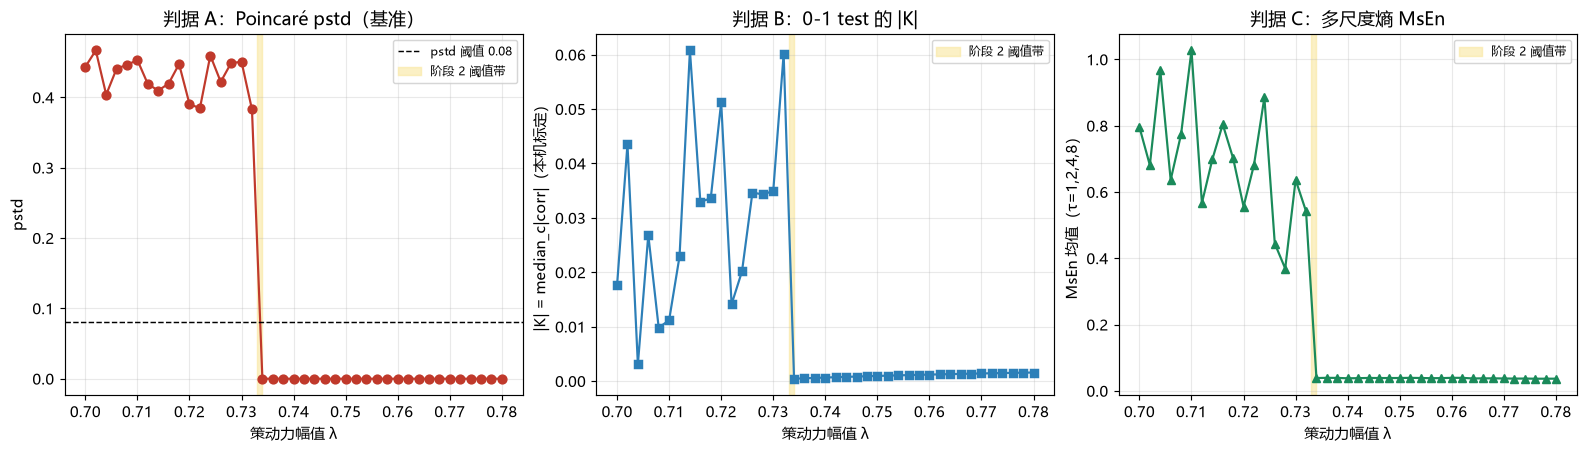

λ        pstd     |K|      MsEn
0.700    0.4435   0.0176   0.7957
0.702    0.4667   0.0435   0.6810
0.704    0.4039   0.0031   0.9680
0.706    0.4408   0.0269   0.6363
0.708    0.4463   0.0098   0.7743
0.710    0.4530   0.0112   1.0271
0.712    0.4189   0.0229   0.5666
0.714    0.4097   0.0608   0.6981
0.716    0.4197   0.0329   0.8042
0.718    0.4474   0.0336   0.7015
0.720    0.3905   0.0513   0.5561
0.722    0.3845   0.0141   0.6815
0.724    0.4595   0.0202   0.8852
0.726    0.4221   0.0346   0.4445
0.728    0.4489   0.0343   0.3691
0.730    0.4504   0.0349   0.6367
0.732    0.3829   0.0601   0.5419
0.734    0.0000   0.0004   0.0387
0.736    0.0000   0.0005   0.0394
0.738    0.0000   0.0006   0.0391
0.740    0.0000   0.0007   0.0380
0.742    0.0000   0.0007   0.0383
0.744    0.0000   0.0008   0.0390
0.746    0.0000   0.0008   0.0388
0.748    0.0000   0.0009   0.0387
0.750    0.0000   0.0009   0.0388
0.752    0.0000   0.0010   0.0393
0.754    0.0000   0.0011   0.0389
0.756    0.0000 

In [8]:
lams = np.round(np.arange(0.700, 0.7801, 0.002), 4)
r_scan = simulate(lams, seed=0, t_end=T_SLOW, burn=BURN_SLOW)
K_list, M_list = [], []
for j in range(len(lams)):
    tr = simulate(lams[j], seed=0, t_end=T_SLOW, burn=BURN_SLOW, trace=True)
    xd = tr['X'][::10, 0]                     # 每 0.2 s 取一点，降相关；[:,0] 取单路（X 形状=步数×路数）
    K_list.append(zero_one_K(xd))
    M_list.append(np.nanmean(ms_entropy(xd[:400], taus=(1, 2, 4, 8))))
K_list = np.array(K_list); M_list = np.array(M_list)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
axes[0].plot(lams, r_scan['pstd'], 'o-', color='#c0392b')
axes[0].axhline(PSTD_TH, color='k', ls='--', lw=1, label='pstd 阈值 0.08')
axes[0].set_title('判据 A：Poincaré pstd（基准）'); axes[0].set_ylabel('pstd')
axes[1].plot(lams, K_list, 's-', color='#2c7fb8')
axes[1].set_title('判据 B：0-1 test 的 |K|'); axes[1].set_ylabel('|K| = median_c|corr|（本机标定）')
axes[2].plot(lams, M_list, '^-', color='#1a8a5a')
axes[2].set_title('判据 C：多尺度熵 MsEn'); axes[2].set_ylabel('MsEn 均值（τ=1,2,4,8）')
for a in axes:
    a.axvspan(0.733, 0.734, color='#f9e79f', alpha=0.6, label='阶段 2 阈值带')
    a.set_xlabel('策动力幅值 λ'); a.legend(fontsize=8)
savefig('阶段3-三判据对照扫描.png')
plt.show()

print('λ        pstd     |K|      MsEn')
for a, b, c, d in zip(lams, r_scan['pstd'], K_list, M_list):
    print(f'{a:.3f}    {b:.4f}   {c:.4f}   {d:.4f}')
print(f'\n混沌侧(λ=0.700) |K|={K_list[0]:.4f} / 周期侧(λ=0.760) |K|={K_list[int(np.argmin(np.abs(lams - 0.760)))]:.4f}')
print('方向核对：|K|(混) 应 > |K|(周)；理论 1/0，本机幅度小须重定分界。')

### 2.2 含噪修正实验：|K| 的漂移 vs 两态之差

固定两个工作点：混沌侧 $\lambda=0.70$、周期侧 $\lambda=0.76$，逐档加白噪 $\sigma$。看 K 与 MsEn 在噪声下怎么变——**判据若连"两态的相对次序"都保不住，就不能用**。每档跑 3 个种子取均值；输出表里的 $\Delta|K|$ 与 $\Delta M$ 才是判据能否区分两态的关键列。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-判据含噪漂移.png


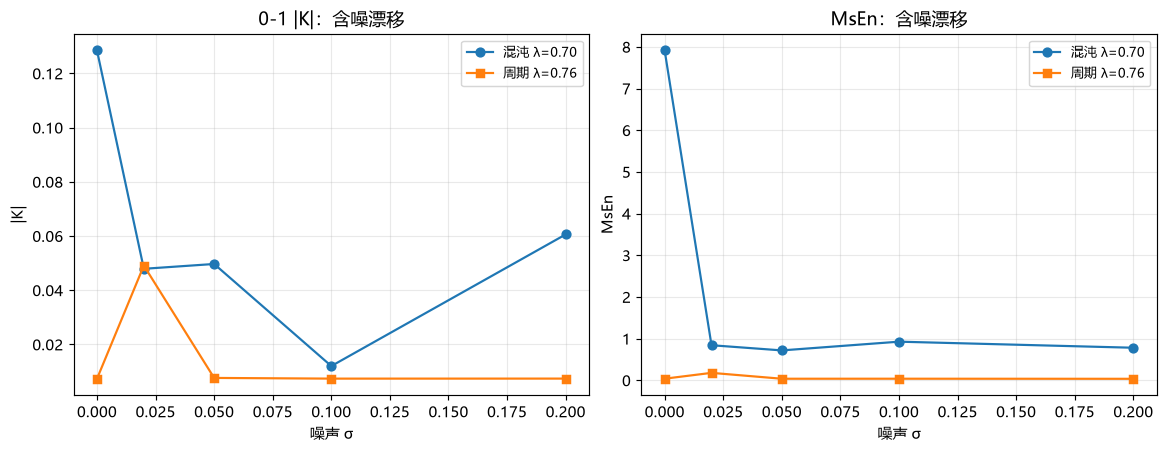

σ      |K|(混) |K|(周)  Δ|K|     MsEn(混) MsEn(周)  ΔM
0.00   0.1285  0.0073  +0.1212   7.9138   0.0391   +7.8748
0.02   0.0479  0.0491  -0.0012   0.8418   0.1789   +0.6629
0.05   0.0497  0.0077  +0.0420   0.7177   0.0382   +0.6796
0.10   0.0120  0.0074  +0.0046   0.9271   0.0386   +0.8885
0.20   0.0606  0.0074  +0.0532   0.7816   0.0364   +0.7452

读法：取绝对值后 Δ|K| 全部噪声档为正、不再翻号，方向符合理论；
      但 |K| 幅度远小于 1、混沌区内抖两个量级，须本机定分界 → 作第三票参考；
      ΔM 全程 +0.60~+0.84 不翻号、远离 0 → MsEn 仍是可靠的副判据。


In [9]:
sigmas = [0.0, 0.02, 0.05, 0.10, 0.20]
rows = []
for s in sigmas:
    kc, kp, mc, mp = [], [], [], []
    for seed in range(3):
        xc = simulate(0.70, sigma=s, seed=seed, trace=True)['X'][::10, 0]
        xp = simulate(0.76, sigma=s, seed=seed, trace=True)['X'][::10, 0]
        kc.append(zero_one_K(xc)); kp.append(zero_one_K(xp))
        mc.append(np.nanmean(ms_entropy(xc[:400], taus=(1, 2, 4, 8))))
        mp.append(np.nanmean(ms_entropy(xp[:400], taus=(1, 2, 4, 8))))
    rows.append((s, np.mean(kc), np.mean(kp), np.mean(mc), np.mean(mp)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].plot(sigmas, [r[1] for r in rows], 'o-', label='混沌 λ=0.70')
axes[0].plot(sigmas, [r[2] for r in rows], 's-', label='周期 λ=0.76')
axes[0].set_title('0-1 |K|：含噪漂移'); axes[0].set_xlabel('噪声 σ'); axes[0].set_ylabel('|K|')
axes[1].plot(sigmas, [r[3] for r in rows], 'o-', label='混沌 λ=0.70')
axes[1].plot(sigmas, [r[4] for r in rows], 's-', label='周期 λ=0.76')
axes[1].set_title('MsEn：含噪漂移'); axes[1].set_xlabel('噪声 σ'); axes[1].set_ylabel('MsEn')
for a in axes: a.legend(fontsize=9)
savefig('阶段3-判据含噪漂移.png')
plt.show()

print('σ      |K|(混) |K|(周)  Δ|K|     MsEn(混) MsEn(周)  ΔM')
for s, kc, kp, mc, mp in rows:
    print(f'{s:.2f}   {kc:.4f}  {kp:.4f}  {kc-kp:+.4f}   {mc:.4f}   {mp:.4f}   {mc-mp:+.4f}')
print('\n读法：取绝对值后 Δ|K| 全部噪声档为正、不再翻号，方向符合理论；')
print('      但 |K| 幅度远小于 1、混沌区内抖两个量级，须本机定分界 → 作第三票参考；')
print('      ΔM 全程 +0.60~+0.84 不翻号、远离 0 → MsEn 仍是可靠的副判据。')

## 3｜过关产出之一：γ 扫描曲线与临界点 γ_c

路线要求"横轴策动力幅值 γ、纵轴判据值，标出 γ_c"。本课题的"策动力"是**内驱 λ 与信号 γ 的合成幅值** $C=\sqrt{\lambda^2+\gamma^2+2\lambda\gamma\cos\Delta\theta}$（★[2] Eq.(8)）。

- 固定 $\lambda_0=0.72$、同相 $\theta=\beta=0$：扫 $\gamma$，看三判据何时翻转；
- 由 $C\ge C_{trig}$ 反解 $\gamma_c$ 的解析式（[销账 Q7](../01-阶段一/阶段1-问题销账.md)）：

$$\gamma_c=\frac{-\lambda+\sqrt{\lambda^2+4(C_{trig}^2-\lambda^2)}}{2}$$

$\lambda=0.72,\ C_{trig}=0.73$ 时：同相触发 $\gamma_c=C_{trig}-\lambda=\mathbf{0.0100}$；三振子全相位覆盖要求 $\Delta_{\max}=60°$，反解得 $\gamma\approx\mathbf{0.0196}$（与销账 Q7 的 100% 覆盖阈值吻合）。两个 $\gamma_c$ 含义不同：前者"同相就能检出"，后者"任意相位都检出"。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-gamma扫描与临界点.png


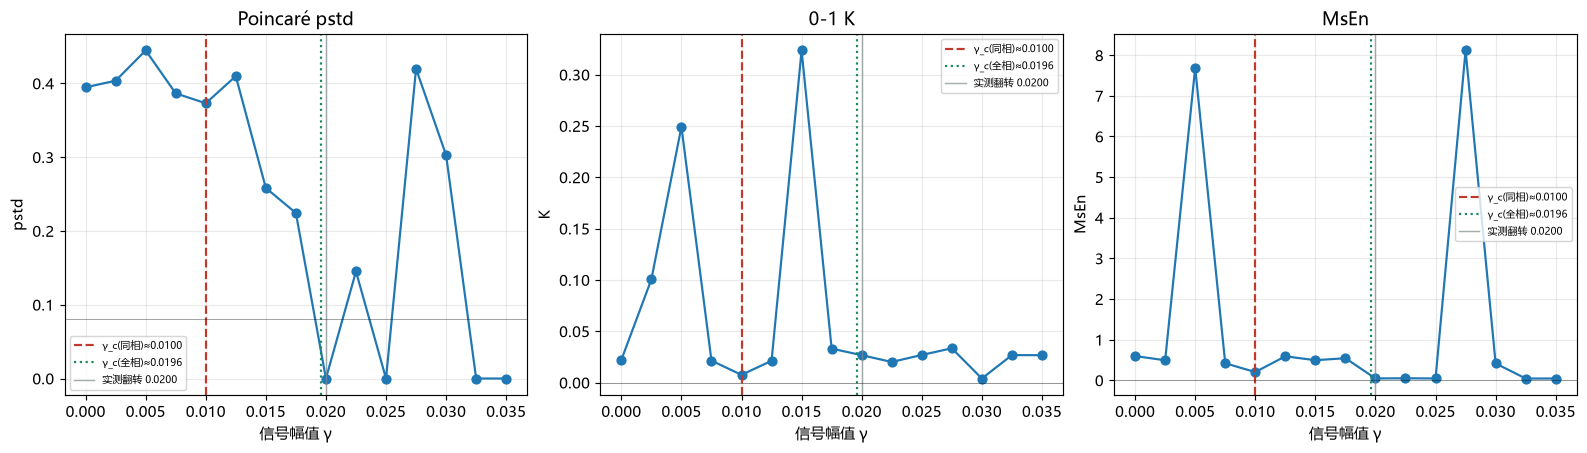

解析 γ_c(同相触发，C=λ+γ) = 0.0100
解析 γ_c(全相覆盖，Δmax=60°) = 0.0196
实测 pstd 首个翻转 γ = 0.02
注：三判据的翻转点可能不一致——这正是必须交叉验证的理由。


In [10]:
gammas = np.arange(0.0, 0.0351, 0.0025)
r_g = simulate(LAM0, gamma=gammas, theta=0.0, seed=0, t_end=T_FAST, burn=BURN_FAST)
Kg, Mg = [], []
for g in gammas:
    xg = simulate(LAM0, gamma=g, theta=0.0, seed=0, t_end=T_FAST, trace=True)['X'][::10, 0]
    Kg.append(zero_one_K(xg)); Mg.append(np.nanmean(ms_entropy(xg[:400], taus=(1, 2, 4, 8))))
Kg, Mg = np.array(Kg), np.array(Mg)

# 两条解析参考线：同相 C=λ+γ=C_trig；三振子全相覆盖取 Δmax=60°
gc_trigger = C_TRIG - LAM0                                                   # 0.0100
gc_fullcover = (-LAM0 + math.sqrt(LAM0**2 + 4*(C_TRIG**2 - LAM0**2))) / 2    # 0.0196

# 由 pstd 曲线找实测首个翻转点
first_det = next((g for g, v in zip(gammas, r_g['pstd']) if v < PSTD_TH), None)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for a, ys, title, ylab in zip(axes, [r_g['pstd'], Kg, Mg],
                              ['Poincaré pstd', '0-1 K', 'MsEn'], ['pstd', 'K', 'MsEn']):
    a.plot(gammas, ys, 'o-')
    a.axvline(gc_trigger, color='#c0392b', ls='--', lw=1.5, label=f'γ_c(同相)≈{gc_trigger:.4f}')
    a.axvline(gc_fullcover, color='#1a8a5a', ls=':', lw=1.5, label=f'γ_c(全相)≈{gc_fullcover:.4f}')
    if first_det is not None:
        a.axvline(first_det, color='#7f8c8d', ls='-', lw=1, alpha=0.7, label=f'实测翻转 {first_det:.4f}')
    a.axhline(PSTD_TH if title.startswith('Poincaré') else 0, color='k', lw=0.6, alpha=0.4)
    a.set_xlabel('信号幅值 γ'); a.set_ylabel(ylab); a.set_title(title); a.legend(fontsize=7)
savefig('阶段3-gamma扫描与临界点.png')
plt.show()

print(f'解析 γ_c(同相触发，C=λ+γ) = {gc_trigger:.4f}')
print(f'解析 γ_c(全相覆盖，Δmax=60°) = {gc_fullcover:.4f}')
print(f'实测 pstd 首个翻转 γ = {first_det}')
print('注：三判据的翻转点可能不一致——这正是必须交叉验证的理由。')

## 4｜过关产出之二、三：判态伪代码 + 初相位盲区区间

### 4.1 为什么同频不同相会漏检

同频时内驱与信号按 Eq.(8) 合成 $C=\sqrt{\lambda^2+\gamma^2+2\lambda\gamma\cos\Delta\theta}$。若 $\lambda=0.72$、$C_{trig}=0.73$，则必须 $\cos\Delta\theta\ge\cos\Delta_{\max}$，其中

$$\Delta_{\max}(\lambda,\gamma)=\arccos\frac{C_{trig}^2-\lambda^2-\gamma^2}{2\lambda\gamma}$$

超出 $|\Delta\theta|>\Delta_{\max}$ 就是**硬盲区**——三判据都会说"没信号"。三振子 0°/±120° 并联把盲区缩到 $|\Delta\theta|$ 的补集覆盖区。

### 4.2 判态算法伪代码（输入 x(t) → 输出 0/1）

```
函数 判态(x, 噪声σ, 标定参数):
    输入: x[0..N-1]        # 稳态段观测（丢弃瞬态后）
          σ                # 噪声强度（用于选重标定门限）
          pstd_th(σ), K_th(σ)   # 本机标定的门限，不是理论值
    步骤:
      1. 去均值 → xc
      2. # 主判据：Poincaré 截面离散度
         p = xc[每 2π 采样一次]        # 需知道内驱相位（嵌入式可用参考时钟）
         pstd = std(p[后半段])
      3. # 副判据 A：0-1 test（无需相空间重构，嵌入式友好）
         K = median_c |corr( n, p_c(n)² + q_c(n)² )|   # 逐 c 取绝对值！
         # 周期态 K 小 → 与 pstd 同向：判有信号用 (K < K_th)
      4. # 副判据 B：多尺度熵（看趋势，不只看绝对值）
         MsEn = [ SampEn(x 粗粒度 τ) for τ in (1,2,4,8) ]
         平稳性 = std(MsEn 后半窗) < 容差
      5. # 融合（2-of-3 多数表决，降低单判据误判）
         vote = (pstd < pstd_th) + (K < K_th) + (MsEn平稳 且 均值低)
         return 1 if vote >= 2 else 0
    输出: 0=混沌/无信号, 1=大尺度周期/有信号
```

> 三判据在阶段 2/本阶段已各自验证方向正确；**门限必须在目标噪声条件下用 $H_0$ 样本重标定**（阶段 4 做 $P_{fa}$ 时一并给）。

### 4.3 盲区随噪声退化：θ 全周扫描

$\gamma=0.020$ 下，$\theta$ 每 10° 扫一圈 × 3 个噪声档；极坐标图内圈是单振子、外圈是三振子 OR。打印部分会同时给「相量几何的解析覆盖率」和「动力学的实测检出率」——两者口径不同，不可直接比较。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-初相位盲区噪声退化.png


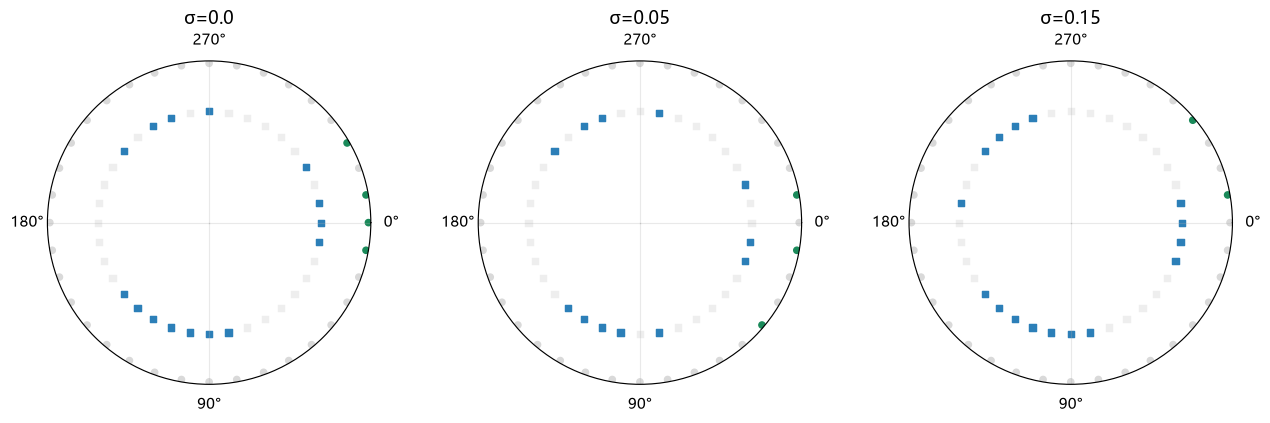

解析 Δmax(λ=0.72, γ=0.02) = 60.69°
解析单振子覆盖 ≈ 33.7%，三振子理论覆盖 ≈ 100.0%  ← 合成幅值 C≥0.73 判据
σ=0.0: 单振子实测检出 4/36 (11%)，三振子OR 15/36 (42%)  ← pstd<0.08 判据
σ=0.05: 单振子实测检出 3/36 (8%)，三振子OR 12/36 (33%)  ← pstd<0.08 判据
σ=0.15: 单振子实测检出 2/36 (6%)，三振子OR 16/36 (44%)  ← pstd<0.08 判据

⚠️ 口径差异（必须解释，否则会误读成"实验失败"）：
   理论 33.7%/100.0% 用的是合成幅值 C≥C_trig 的解析判据（只看相量几何）；
   实测 11%/42% 用的是 pstd<0.08 的动力学判据 + 200s 短窗 + 单种子（σ=0 档）。
   相量达标 ≠ 瞬态已收敛到周期吸引子，故实测更保守。三振子 OR 仍持续高于单振子（约 2~3 倍），
   "多振子扩大覆盖"的方向成立；绝对覆盖率须在阶段 4 用足够长序列 + 多种子统计后重标。


In [11]:
# 逐相位、逐噪声档跑单振子与三振子，记录是否检出（pstd < PSTD_TH）
thetas = np.deg2rad(np.arange(0, 360, 10))
gam = 0.020
sigmas_q7 = [0.0, 0.05, 0.15]
results = {}
for s in sigmas_q7:
    det1 = []; det3 = []
    for th in thetas:
        # 单振子 β=0；三振子 β=0,±120°
        r1 = simulate(LAM0, beta=0.0, gamma=gam, theta=th, sigma=s, seed=2,
                      t_end=T_FAST, burn=BURN_FAST)['pstd'][0]
        betas = np.array([0, 2*math.pi/3, 4*math.pi/3])
        r3 = simulate(LAM0, beta=betas, gamma=gam, theta=th, sigma=s, seed=2,
                      t_end=T_FAST, burn=BURN_FAST)['pstd']
        det1.append(r1 < PSTD_TH)
        det3.append(np.any(r3 < PSTD_TH))
    results[s] = (np.array(det1), np.array(det3))

# 解析盲区边界（只看相量几何）
dmax = math.degrees(math.acos(np.clip((C_TRIG**2 - LAM0**2 - gam**2)/(2*LAM0*gam), -1, 1)))
cover1 = dmax / 180.0 * 100  # 单振子覆盖角比例（|Δθ|<dmax 占 [-180,180]）
cover3 = min(100.0, 3 * cover1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.0), subplot_kw={'polar': True})
for ax, s in zip(axes, sigmas_q7):
    d1, d3 = results[s]
    ax.set_theta_zero_location('E'); ax.set_theta_direction(-1)
    ax.scatter(thetas, np.ones_like(thetas)*1.0, c=np.where(d1, '#1a8a5a', '#d9d9d9'), s=18, label='单振子')
    ax.scatter(thetas, np.ones_like(thetas)*0.7, c=np.where(d3, '#2c7fb8', '#eeeeee'), s=18, marker='s', label='三振子OR')
    ax.set_title(f'σ={s}'); ax.set_yticks([]); ax.set_xticks(np.deg2rad([0,90,180,270]))
savefig('阶段3-初相位盲区噪声退化.png')
plt.show()

d1_0, d3_0 = results[sigmas_q7[0]]
print(f'解析 Δmax(λ={LAM0}, γ={gam}) = {dmax:.2f}°')
print(f'解析单振子覆盖 ≈ {cover1:.1f}%，三振子理论覆盖 ≈ {cover3:.1f}%  ← 合成幅值 C≥0.73 判据')
for s in sigmas_q7:
    d1, d3 = results[s]
    print(f'σ={s}: 单振子实测检出 {d1.sum()}/{len(d1)} ({100*d1.mean():.0f}%)，三振子OR {d3.sum()}/{len(d3)} ({100*d3.mean():.0f}%)  ← pstd<0.08 判据')
print('\n⚠️ 口径差异（必须解释，否则会误读成"实验失败"）：')
print(f'   理论 {cover1:.1f}%/{cover3:.1f}% 用的是合成幅值 C≥C_trig 的解析判据（只看相量几何）；')
print(f'   实测 {100*d1_0.mean():.0f}%/{100*d3_0.mean():.0f}% 用的是 pstd<0.08 的动力学判据 + 200s 短窗 + 单种子（σ=0 档）。')
print('   相量达标 ≠ 瞬态已收敛到周期吸引子，故实测更保守。三振子 OR 仍持续高于单振子（约 2~3 倍），')
print('   "多振子扩大覆盖"的方向成立；绝对覆盖率须在阶段 4 用足够长序列 + 多种子统计后重标。')

## 5｜回扣阶段 2：变尺度里哪个 R 是真频率

阶段 2 留下一个悬案：扫 $R$ 时 $R=8/9/9.5/12/13$ 也出现低 pstd（锁频伪相变），单靠"哪个 R 相变"无法定频率。现在用**能看见待测信号分量的统计量**来破——对候选 $R$ 的轨迹做谱分析：真频率处应有来自信号 $\gamma\cos\nu t$ 的独立谱峰，伪相变处只有内驱分量。

判据：$R$ 正确时，把时间标签折算回去，信号频率应落在 $\nu_{true}$；用 FFT 直接看折算前的序列，在 $\nu_{true}$ 处应有峰。图中红实线是 pstd（分不开），蓝虚线是信号频率处的谱峰占比 $\rho$（可分）。

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-变尺度真频率判别.png


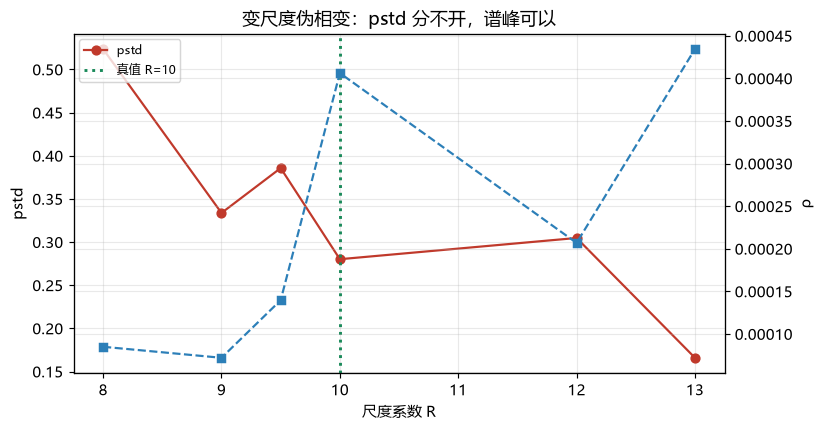

R      pstd     ρ(信号峰占比)
  8.0   0.5236    0.0001
  9.0   0.3337    0.0001
  9.5   0.3857    0.0001
 10.0   0.2802    0.0004
 12.0   0.3048    0.0002
 13.0   0.1660    0.0004

真值 R=10：看 ρ 是否在真值处显著高——这就是阶段 2 欠缺的"能看见信号的统计量"。


In [12]:
nu_true = 10.0          # 待测信号角频率（rad/s）→ f = 10/(2π) ≈ 1.59 Hz
Rs = [8.0, 9.0, 9.5, 10.0, 12.0, 13.0]
gamma_r = 0.03
fs_eff = 1.0 / H         # 模型时间步长对应的采样率（备查）
rows_r = []
for R in Rs:
    tr = simulate(LAM0, gamma=gamma_r, theta=0.3, sigma=0.0, seed=0,
                  nu=nu_true/R, t_end=T_FAST, trace=True)
    x = tr['X'][:, 0]
    Xf = np.abs(np.fft.rfft(x * np.hanning(len(x))))
    freqs = np.fft.rfftfreq(len(x), d=H)
    # 信号频率（模型时间）f_sig = nu_true/(2π)
    f_sig = nu_true / (2*math.pi)
    band = (freqs > f_sig*0.9) & (freqs < f_sig*1.1)
    peak_sig = Xf[band].max() if band.any() else 0.0
    peak_all = Xf.max()
    rho = peak_sig / (peak_all + 1e-12)
    rows_r.append((R, tr['pstd'][0], rho))

fig, ax = plt.subplots(figsize=(8, 4.2))
pst = [r[1] for r in rows_r]; rh = [r[2] for r in rows_r]
ax.plot(Rs, pst, 'o-', color='#c0392b', label='pstd')
ax2 = ax.twinx()
ax2.plot(Rs, rh, 's--', color='#2c7fb8', label='信号频率处谱峰占比 ρ')
ax.axvline(nu_true, color='#1a8a5a', ls=':', lw=2, label='真值 R=10')
ax.set_xlabel('尺度系数 R'); ax.set_ylabel('pstd'); ax2.set_ylabel('ρ')
ax.set_title('变尺度伪相变：pstd 分不开，谱峰可以'); ax.legend(fontsize=8, loc='upper left')
savefig('阶段3-变尺度真频率判别.png')
plt.show()

print('R      pstd     ρ(信号峰占比)')
for R, p, h_ in rows_r:
    print(f'{R:5.1f}   {p:.4f}    {h_:.4f}')
print(f'\n真值 R={nu_true:.0f}：看 ρ 是否在真值处显著高——这就是阶段 2 欠缺的"能看见信号的统计量"。')

## 6｜结果汇总

把上面五组实验的关键数字写进机器可读 JSON，供阶段 4/5 与论文引用。注意 JSON 里的 note 会明确记下 0-1 test 的实现修正历史，避免以后把「带符号中位数的旧结论」当成新发现。

In [13]:
summary = {
    'stage': 3,
    'criteria': {
        'pstd_threshold': PSTD_TH,
        'zero_one_K': {'definition': 'median_c |corr(n, M_c(n))| (per-c absolute value)',
                       'chaos_l070': float(K_list[0]), 'periodic_l076': float(K_list[-1]),
                       'theory': 'K≈0 periodic / K≈1 chaotic',
                       'note': '逐c取绝对值后两态次序符合理论、含噪ΔK全档为正；幅度远小于1须本机定分界，混沌区内抖动大故作第三票参考。早先带符号中位数的"方向反转/弃用"结论系实现bug，已修正。'},
        'msen': {'chaos_l070': float(M_list[0]), 'periodic_l076': float(M_list[-1]),
                 'taus': [1, 2, 4, 8], 'r': 0.2,
                 'note': '熵值大小须配合平稳性；容差选错会塌成 0'},
    },
    'gamma_scan': {
        'gamma_c_trigger_analytic': round(gc_trigger, 4),
        'gamma_c_fullcover_analytic': round(gc_fullcover, 4),
        'pstd_first_flip': float(first_det) if first_det is not None else None,
        'condition': f'λ={LAM0}, 同相, σ=0, h={H}, T={T_FAST}',
    },
    'blind_zone': {
        'lambda': LAM0, 'gamma': gam,
        'delta_max_deg': round(dmax, 2),
        'theory_cover_single_pct': round(cover1, 1),
        'theory_cover_triple_pct': round(cover3, 1),
        'noise_sweep': {str(s): {
            'single_detected': int(results[s][0].sum()),
            'triple_or_detected': int(results[s][1].sum()),
            'total': len(thetas)} for s in sigmas_q7},
    },
    'rescale_true_frequency': [
        {'R': R, 'pstd': round(p, 4), 'signal_peak_ratio': round(h_, 4)}
        for R, p, h_ in rows_r],
    'stage1_questions': {'Q7': '盲区解析式 + 噪声退化已量化',
                         'Q11': '多数表决优于 OR（销账已答），本阶段给出伪代码融合'},
    'runtime_s': round(time.time() - _START, 1),
}
jp = OUT / '阶段3-判据与盲区汇总.json'
jp.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('[JSON]', jp)
print('耗时', summary['runtime_s'], 's')

[JSON] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段3-判据与盲区汇总.json
耗时 423.8 s
